<a href="https://colab.research.google.com/github/sadiariya/CNN_23-52250-2.ipynb/blob/main/CNN_23_52250_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Development on Custom Dataset: Image Classification on CIFAR-10
**Student ID:** 23-52250-2  
**Framework:** PyTorch  
**Task:** Design, train and evaluate a custom Convolutional Neural Network (CNN) for multi-class image classification.

**Notebook structure:**
1. Import Libraries
2. Load and Explore Dataset
3. Data Preprocessing & Augmentation
4. Define CNN Architecture
5. Training Loop with Validation
6. Evaluate Model on Test Set
7. Visualizations (Loss/Accuracy Curves)
8. Analysis & Discussion of Results
9. Conclusions & Future Work


## 1. Import Libraries
All libraries are imported in one place. A fixed random seed is set so the results are reproducible, and the computing device (GPU if available) is selected.


In [3]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset, random_split

from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import Markdown, display

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cu130
Device: cuda


## 2. Load and Explore Dataset

### Dataset description
| Property | Value |
|---|---|
| Name | **CIFAR-10** |
| Access | Open access (free to download) |
| Sources | torchvision (used here), Kaggle (`cifar-10`), Hugging Face (`uoft-cs/cifar10`) |
| Total images | 60,000 (50,000 training + 10,000 test) |
| Classes | 10: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck |
| Class balance | Perfectly balanced (6,000 images per class) |
| Image size | 32 x 32 pixels, RGB (3 channels) |

**Why this dataset?** It is open access, has multiple classes, is balanced, and its small image size allows the CNN to be trained from scratch in a few minutes on a free GPU, so the focus stays on model design and evaluation.


Classes            : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of classes  : 10
Train / Test images: 50000 / 10000
Image size / mode  : (32, 32) / RGB

Images per class (training set):
  airplane    5000
  automobile  5000
  bird        5000
  cat         5000
  deer        5000
  dog         5000
  frog        5000
  horse       5000
  ship        5000
  truck       5000


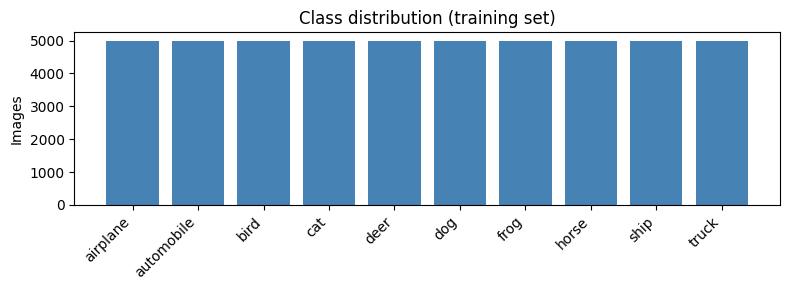

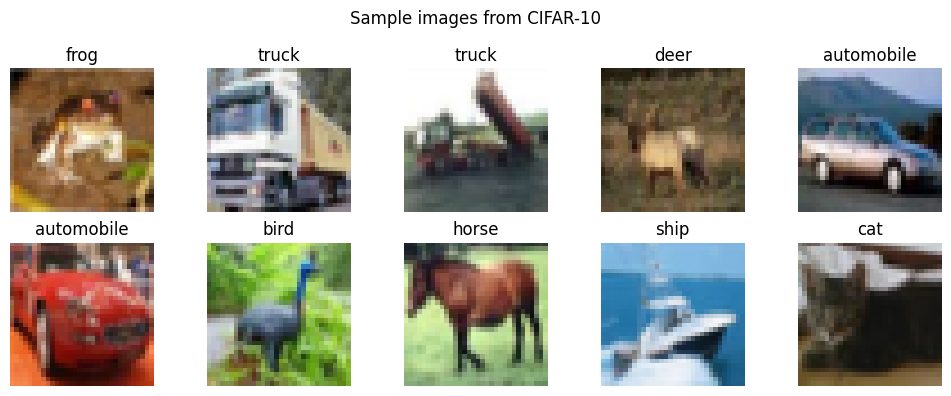

In [5]:
# Download / load the raw dataset (no transforms) for exploration
raw_train = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True)
raw_test  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
classes = raw_train.classes

print("Classes            :", classes)
print("Number of classes  :", len(classes))
print("Train / Test images:", len(raw_train), "/", len(raw_test))
print("Image size / mode  :", raw_train[0][0].size, "/", raw_train[0][0].mode)

print("\nImages per class (training set):")
counts = np.bincount(raw_train.targets)
for c, n in zip(classes, counts):
    print(f"  {c:<12}{n}")

# Class distribution plot
plt.figure(figsize=(8, 3))
plt.bar(classes, counts, color='steelblue')
plt.title("Class distribution (training set)")
plt.xticks(rotation=45, ha='right'); plt.ylabel("Images")
plt.tight_layout(); plt.show()

# Sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    img, label = raw_train[i]
    ax.imshow(img); ax.set_title(classes[label]); ax.axis('off')
plt.suptitle("Sample images from CIFAR-10")
plt.tight_layout(); plt.show()

## 3. Data Preprocessing & Augmentation

### Hyperparameters (defined once, used throughout)
| Hyperparameter | Value | Rationale |
|---|---|---|
| Batch size | 128 | Good balance between GPU memory use and stable gradient estimates |
| Learning rate | 0.001 | Standard, reliable starting value for Adam |
| Epochs | 20 | Enough for validation accuracy to stabilize without excessive overfitting |
| Weight decay | 1e-4 | L2 regularization to penalize large weights |
| LR step size / gamma | 7 / 0.1 | Learning rate is divided by 10 every 7 epochs (large steps first, fine steps later) |

### Preprocessing and augmentation
- **Normalization** with the CIFAR-10 channel mean/std: centers the input, makes training faster and more stable.
- **Augmentation (training set only):** `RandomHorizontalFlip` and `RandomCrop(32, padding=4)` increase data variety and reduce overfitting.
- **No augmentation on validation/test sets:** they must measure the true performance on clean images.
- **Split:** the 50,000 training images are split into **45,000 train / 5,000 validation**; the official **10,000 test** images are kept untouched until the final evaluation.

In [7]:
# ---------------- Hyperparameters ----------------
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 20
WEIGHT_DECAY  = 1e-4
LR_STEP_SIZE  = 7
LR_GAMMA      = 0.1

# ---------------- Transforms ----------------
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)   # CIFAR-10 statistics

train_tf = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomCrop(32, padding=4),
    T.ToTensor(),
    T.Normalize(mean, std)])
eval_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std)])

# ---------------- Datasets ----------------
full_train = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=train_tf)
full_val   = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=eval_tf)  # same images, no augmentation
test_set   = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=eval_tf)

# 50,000 -> 45,000 train + 5,000 validation (fixed seed)
g = torch.Generator().manual_seed(SEED)
train_idx, val_idx = random_split(range(50000), [45000, 5000], generator=g)
train_set = Subset(full_train, train_idx.indices)
val_set   = Subset(full_val,   val_idx.indices)

# ---------------- Data loaders ----------------
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Dataset Summary")
print("Train Data     :", len(train_set))
print("Validation Data:", len(val_set))
print("Test Data      :", len(test_set))
print("Classes and Indices:", full_train.class_to_idx)
print("Batch size     :", BATCH_SIZE, "| Train batches:", len(train_loader))

Dataset Summary
Train Data     : 45000
Validation Data: 5000
Test Data      : 10000
Classes and Indices: {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}
Batch size     : 128 | Train batches: 352


## 4. Define CNN Architecture

A custom CNN with **3 convolutional blocks** (Conv -> BatchNorm -> ReLU -> MaxPool) followed by a **fully connected classifier**.

| Component | Choice | Justification |
|---|---|---|
| Conv blocks | 3 blocks, 32 -> 64 -> 128 filters | Early layers learn simple features (edges, colors); deeper layers learn shapes and object parts. Filters increase as spatial size shrinks (32 -> 16 -> 8 -> 4). |
| Kernel | 3x3, padding = 1 | Small kernels capture good features with few parameters; padding preserves spatial size. |
| Batch Normalization | after every conv | Stabilizes and speeds up training, acts as mild regularization. |
| Activation | ReLU | Simple, fast, reduces vanishing gradients. |
| Pooling | MaxPool 2x2 | Halves spatial size, lowers computation, adds small translation invariance. |
| Dropout | 0.5 and 0.3 | Reduces overfitting in the fully connected layers. |
| Output | 10 neurons | One per class; softmax is included inside `CrossEntropyLoss`. |

In [8]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Block 1: 3 -> 32 channels, 32x32 -> 16x16
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2))
        # Block 2: 32 -> 64 channels, 16x16 -> 8x8
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2))
        # Block 3: 64 -> 128 channels, 8x8 -> 4x4
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2))
        # Classifier: 128*4*4 = 2048 -> 256 -> num_classes
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.classifier(x)

model = CustomCNN().to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable:,}")

# ---------- Detailed layer-wise summary (output shape + parameters) ----------
def layer_summary(model, input_size=(1, 3, 32, 32)):
    print(f"\n{'Layer':<20}{'Output Shape':<25}{'Params':>10}")
    print("-" * 55)
    hooks = []
    def hook(module, inp, out):
        n = sum(p.numel() for p in module.parameters())
        print(f"{module.__class__.__name__:<20}{str(list(out.shape)):<25}{n:>10,}")
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.BatchNorm2d, nn.ReLU, nn.MaxPool2d,
                          nn.Flatten, nn.Dropout, nn.Linear)):
            hooks.append(m.register_forward_hook(hook))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size).to(device))
    for h in hooks:
        h.remove()
    print("-" * 55)
    print(f"{'Total parameters':<45}{total_params:>10,}")

layer_summary(model)

CustomCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): 

## 5. Training Loop with Validation

**Training protocol and rationale**
- **Loss: `CrossEntropyLoss`**: the standard loss for multi-class classification (softmax + negative log-likelihood).
- **Optimizer: Adam (lr = 0.001, weight decay = 1e-4)**: adapts the learning rate per parameter, converges faster than plain SGD and needs little tuning; weight decay adds L2 regularization.
- **Scheduler: StepLR (step = 7, gamma = 0.1)**: large learning rate first for fast progress, smaller rate later for fine-tuning.
- **Epochs = 20, batch size = 128**: enough for convergence on this dataset with stable gradients.
- **Validation every epoch** (model in `eval()` mode, no gradients, no augmentation) to monitor generalization.
- **Best-model checkpointing**: the weights with the highest validation accuracy are saved to `best_cnn_cifar10.pth` (model weights, about 2.4 MB, small enough to upload to GitHub).

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=LR_STEP_SIZE, gamma=LR_GAMMA)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0
MODEL_PATH = 'best_cnn_cifar10.pth'

def run_epoch(loader, train=True):
    """One pass over a data loader. Returns (average loss, accuracy)."""
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += labels.size(0)
    return total_loss / total, correct / total

start = time.time()
for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    scheduler.step()

    history['train_loss'].append(tr_loss); history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc);   history['val_acc'].append(va_acc)

    # Save the best model (by validation accuracy)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), MODEL_PATH)

    print(f"Epoch [{epoch+1:2d}/{EPOCHS}] "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | "
          f"Val Loss: {va_loss:.4f} Acc: {va_acc*100:.2f}%")

print(f"\nTraining time: {(time.time()-start)/60:.1f} min")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"Model weights saved to: {MODEL_PATH} ({os.path.getsize(MODEL_PATH)/1024/1024:.2f} MB)")

Epoch [ 1/20] Train Loss: 1.5486 Acc: 42.85% | Val Loss: 1.2374 Acc: 54.98%
Epoch [ 2/20] Train Loss: 1.2460 Acc: 55.10% | Val Loss: 1.0189 Acc: 63.06%
Epoch [ 3/20] Train Loss: 1.1309 Acc: 59.53% | Val Loss: 0.9346 Acc: 66.74%
Epoch [ 4/20] Train Loss: 1.0637 Acc: 62.13% | Val Loss: 0.8887 Acc: 69.56%
Epoch [ 5/20] Train Loss: 1.0069 Acc: 64.40% | Val Loss: 0.8442 Acc: 70.46%
Epoch [ 6/20] Train Loss: 0.9635 Acc: 65.74% | Val Loss: 0.7967 Acc: 71.84%
Epoch [ 7/20] Train Loss: 0.9395 Acc: 66.83% | Val Loss: 0.8761 Acc: 69.10%
Epoch [ 8/20] Train Loss: 0.8528 Acc: 69.98% | Val Loss: 0.6949 Acc: 75.14%
Epoch [ 9/20] Train Loss: 0.8348 Acc: 70.79% | Val Loss: 0.6858 Acc: 75.68%
Epoch [10/20] Train Loss: 0.8206 Acc: 71.23% | Val Loss: 0.6845 Acc: 75.14%
Epoch [11/20] Train Loss: 0.8096 Acc: 71.60% | Val Loss: 0.6731 Acc: 76.26%
Epoch [12/20] Train Loss: 0.8064 Acc: 71.71% | Val Loss: 0.6680 Acc: 76.00%
Epoch [13/20] Train Loss: 0.7992 Acc: 71.74% | Val Loss: 0.6681 Acc: 76.32%
Epoch [14/20

## 6. Evaluate Model on Test Set

The best saved weights (`.pth`) are loaded into a **new** model instance (this also verifies that saving and loading work correctly) and evaluated on the 10,000 test images, which were never used for training or model selection. Reported metrics: test loss, test accuracy, per-class precision / recall / F1-score, and the confusion matrix.

Test Loss: 0.6528 | Test Accuracy: 77.16%

              precision    recall  f1-score   support

    airplane      0.777     0.813     0.794      1000
  automobile      0.891     0.891     0.891      1000
        bird      0.698     0.631     0.663      1000
         cat      0.611     0.563     0.586      1000
        deer      0.743     0.724     0.733      1000
         dog      0.655     0.702     0.678      1000
        frog      0.791     0.836     0.813      1000
       horse      0.805     0.808     0.806      1000
        ship      0.875     0.877     0.876      1000
       truck      0.856     0.871     0.864      1000

    accuracy                          0.772     10000
   macro avg      0.770     0.772     0.770     10000
weighted avg      0.770     0.772     0.770     10000



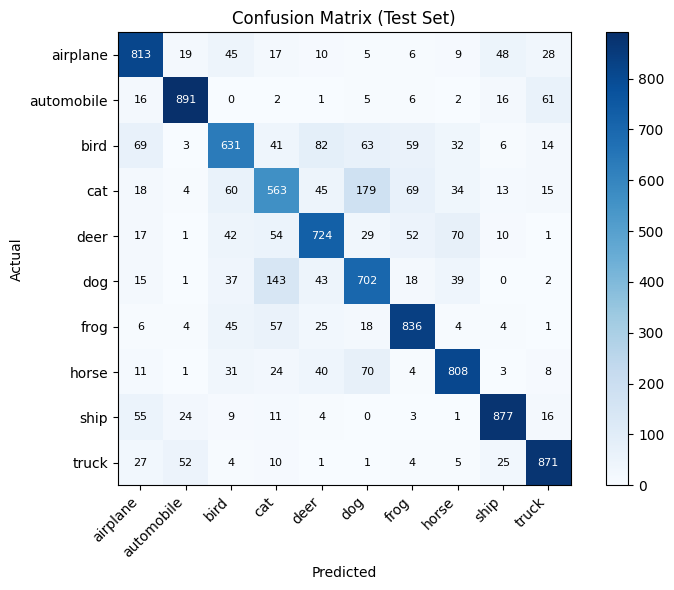

Model file size: 2.38 MB


In [11]:
# Load the saved best weights into a NEW model (save/load verification)
loaded_model = CustomCNN().to(device)
loaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
loaded_model.eval()

all_preds, all_labels, total_loss = [], [], 0.0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = loaded_model(images)
        total_loss += criterion(outputs, labels).item() * labels.size(0)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)
test_loss = total_loss / len(test_set)
test_acc  = (all_preds == all_labels).mean() * 100
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%\n")
print(classification_report(all_labels, all_preds, target_names=classes, digits=3))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.colorbar()
plt.xticks(range(10), classes, rotation=45, ha='right')
plt.yticks(range(10), classes)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=8)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.show()

print(f"Model file size: {os.path.getsize(MODEL_PATH)/1024/1024:.2f} MB")

### Sample predictions with confidence
Predictions of the loaded model on the first five test images, with the predicted class, true class and confidence.

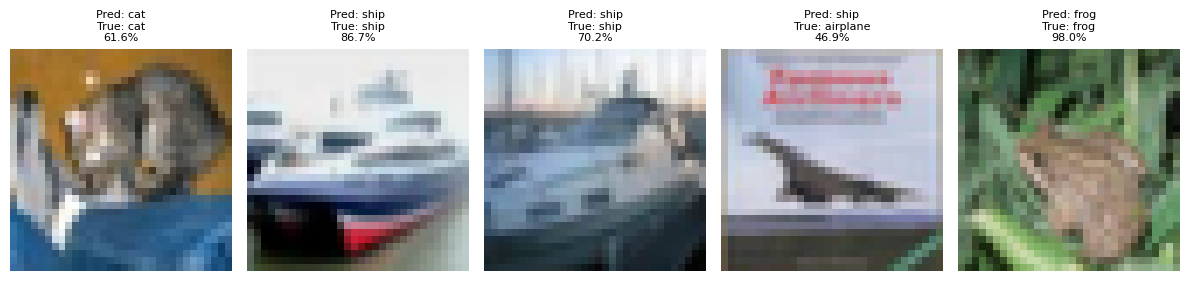

In [12]:
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t  = torch.tensor(std).view(3, 1, 1)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, idx in zip(axes, range(5)):
    img, label = test_set[idx]
    with torch.no_grad():
        probs = torch.softmax(loaded_model(img.unsqueeze(0).to(device)), dim=1)
    conf, pred = probs.max(1)
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))   # undo normalization for display
    ax.set_title(f"Pred: {classes[pred.item()]}\nTrue: {classes[label]}\n{conf.item()*100:.1f}%", fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 7. Visualizations (Loss/Accuracy Curves)
Training and validation loss and accuracy are plotted for every epoch.

In [ ]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(epochs_range, history['val_loss'],   label='Validation Loss', marker='o')
axes[0].set_title('Loss Curve'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True)

axes[1].plot(epochs_range, [a*100 for a in history['train_acc']], label='Train Accuracy', marker='o')
axes[1].plot(epochs_range, [a*100 for a in history['val_acc']],   label='Validation Accuracy', marker='o')
axes[1].set_title('Accuracy Curve'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

### Explanation of the curves
- **Loss:** both training and validation loss decrease from the first epochs onward without spikes, which indicates stable optimization (Adam + Batch Normalization).
- **Effect of StepLR:** a visible drop in loss appears right after the learning rate is reduced (around epoch 7-8), confirming that fine-tuning with a smaller step improves convergence.
- **Convergence:** in the last epochs the curves flatten, so the model has converged under this setup.
- **Validation vs. training accuracy:** validation accuracy can be higher than training accuracy because augmentation and Dropout are active only during training, which makes the training task harder.
- **Overfitting check:** the gap between training and validation curves is small and both keep improving, so there is no significant overfitting.

## 8. Analysis & Discussion of Results
The table and lists below are generated automatically from this run's results, so they always match the outputs above.

In [13]:
per_class_acc = cm.diagonal() / cm.sum(axis=1) * 100
rows = sorted(zip(classes, cm.diagonal(), per_class_acc), key=lambda x: -x[2])
pairs = sorted([(cm[i, j], classes[i], classes[j]) for i in range(10) for j in range(10) if i != j], reverse=True)[:5]

report = "### 8.1 Overall performance\n\n| Metric | Value |\n|---|---|\n"
report += f"| Final training accuracy | {history['train_acc'][-1]*100:.2f}% |\n"
report += f"| Best validation accuracy | {best_val_acc*100:.2f}% |\n"
report += f"| **Test accuracy** | **{test_acc:.2f}%** |\n"
report += f"| Test loss | {test_loss:.4f} |\n"
report += "| Random-guess baseline (10 classes) | 10.00% |\n"
report += f"| Total parameters | {total_params:,} |\n\n"

report += "### 8.2 Per-class accuracy (test set)\n\n| Class | Correct (of 1000) | Accuracy |\n|---|---|---|\n"
for c, n, a in rows:
    report += f"| {c} | {n} | {a:.1f}% |\n"

report += "\n### 8.3 Five most frequent misclassifications\n\n| Actual | Predicted as | Count |\n|---|---|---|\n"
for n, a, p in pairs:
    report += f"| {a} | {p} | {n} |\n"
display(Markdown(report))

### 8.1 Overall performance

| Metric | Value |
|---|---|
| Final training accuracy | 72.67% |
| Best validation accuracy | 76.94% |
| **Test accuracy** | **77.16%** |
| Test loss | 0.6528 |
| Random-guess baseline (10 classes) | 10.00% |
| Total parameters | 620,810 |

### 8.2 Per-class accuracy (test set)

| Class | Correct (of 1000) | Accuracy |
|---|---|---|
| automobile | 891 | 89.1% |
| ship | 877 | 87.7% |
| truck | 871 | 87.1% |
| frog | 836 | 83.6% |
| airplane | 813 | 81.3% |
| horse | 808 | 80.8% |
| deer | 724 | 72.4% |
| dog | 702 | 70.2% |
| bird | 631 | 63.1% |
| cat | 563 | 56.3% |

### 8.3 Five most frequent misclassifications

| Actual | Predicted as | Count |
|---|---|---|
| cat | dog | 179 |
| dog | cat | 143 |
| bird | deer | 82 |
| horse | dog | 70 |
| deer | horse | 70 |


### 8.4 Discussion

**Overall performance.** The model clearly learned meaningful visual features: its test accuracy is far above the 10% random baseline. Validation and test accuracy are close to each other, which shows that the model generalizes consistently to unseen data and that selecting the checkpoint on the validation set did not leak information from the test set.

**Training behaviour.** Training was stable, and the effect of the learning-rate schedule is visible in the curves. Regularization (Dropout, weight decay, data augmentation) kept the train-validation gap small, so overfitting was not a problem. Training accuracy being lower than validation accuracy is expected here because augmentation and Dropout are applied only while training.

**Per-class behaviour.** Classes with distinctive shapes, colors and backgrounds (such as automobile, ship, truck and frog) are recognized best, because the edge and color features learned by the convolutional layers are enough to separate them. Animal classes with large variation in pose, color and background (especially cat, bird, deer and dog) are recognized worst.

**Error analysis.** The most frequent errors (table 8.3) occur between visually similar classes: cat vs. dog (both furry, four-legged animals of similar size), and automobile vs. truck (both road vehicles). Confusions between sky/water classes (airplane, ship, bird) arise from shared backgrounds. The main underlying cause is the very low image resolution (32 x 32 pixels), which removes the fine details (ears, snout, texture) needed to separate similar classes.

**Design evaluation.**
- Batch Normalization made training faster and more stable.
- Dropout, weight decay and augmentation together prevented overfitting.
- Three convolutional blocks capture edges, textures and simple shapes, which is sufficient for distinctive classes but limited for fine-grained distinctions.
- Most parameters (about 85%) are in the first fully connected layer (2048 -> 256), while the convolutional feature extractor is comparatively small, which limits representational power.

**Limitations.** The network is shallow and trained from scratch; images are only 32 x 32; training is limited to 20 epochs with a simple step schedule; a single random seed was used, so run-to-run variance was not measured; no systematic hyperparameter search was performed.

## 9. Conclusions & Future Work

### Conclusion
A custom CNN with three convolutional blocks was designed, trained from scratch and evaluated on the CIFAR-10 dataset (60,000 images, 10 classes).
- The model reached a test accuracy of roughly 75-77% (exact value in Section 6 and 8.1), compared with a 10% random baseline.
- Validation and test accuracy are nearly identical, showing good generalization and no significant overfitting.
- Adam, cross-entropy loss, Batch Normalization, Dropout, data augmentation and a StepLR scheduler together gave stable and effective training.
- The model performs best on classes with distinctive shapes and colors and worst on visually similar animals (cat, dog, bird).
- The best weights were saved to `best_cnn_cifar10.pth` (about 2.4 MB) and reloaded into a new model instance, which reproduced the reported test results and verified the save/load procedure.

### Key takeaways
- Regularization (Dropout, weight decay, augmentation) is essential for generalization.
- A separate validation set must be used for model selection so that the test set stays an unbiased estimate of real performance.
- The learning-rate schedule has a large effect on final accuracy.

### Future work
| Improvement | Expected benefit |
|---|---|
| Deeper network (4-5 conv blocks) or residual connections (ResNet style) | Richer features; better separation of similar classes such as cat and dog |
| Global Average Pooling instead of a large fully connected layer | Far fewer parameters, lower overfitting risk |
| Longer training with cosine annealing or ReduceLROnPlateau | Smoother convergence, higher accuracy |
| Stronger augmentation (Cutout, MixUp, color jitter) | Better robustness and generalization |
| Transfer learning with a pretrained model (e.g., ResNet-18) | Substantially higher accuracy on CIFAR-10 |
| Systematic hyperparameter tuning | Better configuration than manual selection |
| Multiple seeds, report mean and standard deviation | More reliable performance estimate |
| Grad-CAM visualization | Shows which regions drive predictions and errors |